import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Loading the dataset

In [129]:
netflix=pd.read_clipboard()

In [130]:
netflix.shape

(24812, 6)

In [131]:
netflix.head(5)

,Title,Available Globally?,Release Date,Hours Viewed,Language Indicator,Content Type
0,The Night Agent: Season 1,Yes,23-03-2023,"81,21,00,000",English,Show
1,Ginny & Georgia: Season 2,Yes,05-01-2023,"66,51,00,000",English,Show
2,The Glory: Season 1 // 더 글로리: 시즌 1,Yes,30-12-2022,"62,28,00,000",Korean,Show
3,Wednesday: Season 1,Yes,23-11-2022,"50,77,00,000",English,Show
4,Queen Charlotte: A Bridgerton Story,Yes,04-05-2023,"50,30,00,000",English,Movie


# Data Inspection and Cleaning

In [ ]:
# Making an external copy

In [27]:
netflix_copy=netflix.copy()

In [28]:
netflix_copy.shape

(24812, 6)

In [ ]:
#Checking Duplicates

In [140]:
netflix_copy["Title"].duplicated().sum()

np.int64(5187)

In [ ]:
#Removing duplicates

In [154]:
netflix_copy = netflix_copy.drop_duplicates(subset=["Title"])

In [155]:
netflix_copy["Title"].duplicated().sum()

np.int64(0)

In [156]:
netflix_copy.shape

(19158, 6)

In [ ]:
# Checking null items

In [38]:
netflix_copy.isnull().sum()

Title                      0
Available Globally?        0
Release Date           16370
Hours Viewed               0
Language Indicator         0
Content Type               0
dtype: int64

In [158]:
netflix_copy.dtypes

Title                          object
Available Globally?            object
Release Date           datetime64[ns]
Hours Viewed                    int64
Language Indicator             object
Content Type                   object
dtype: object

In [ ]:
#Which 10 titles have the highest viewing hours?

In [163]:
top_10 = netflix_copy.nlargest(10, "Hours Viewed")[["Title", "Hours Viewed", "Language Indicator", "Content Type"]]
top_10

,Title,Hours Viewed,Language Indicator,Content Type
0,The Night Agent: Season 1,812100000,English,Show
1,Ginny & Georgia: Season 2,665100000,English,Show
2,The Glory: Season 1 // 더 글로리: 시즌 1,622800000,Korean,Show
18214,ONE PIECE: Season 1,541900000,English,Show
3,Wednesday: Season 1,507700000,English,Show
4,Queen Charlotte: A Bridgerton Story,503000000,English,Movie
5,You: Season 4,440600000,English,Show
6,La Reina del Sur: Season 3,429600000,English,Show
7,Outer Banks: Season 3,402500000,English,Show
18219,Sex Education: Season 4,374700000,English,Show


##### The top title with highest viewing hours of 812.1 million viewing hours. Highest viewing hours is mostly affected by Show and movie has very less affect

In [ ]:
#Do Movies or Shows generate more total viewing hours?

In [177]:
result=netflix_copy.groupby(by="Content Type")["Hours Viewed"].sum().sort_values(ascending=False)
result.to_frame(name="Total viewing hours")

,Total viewing hours
Content Type,
Show,68273000000
Movie,43074000000


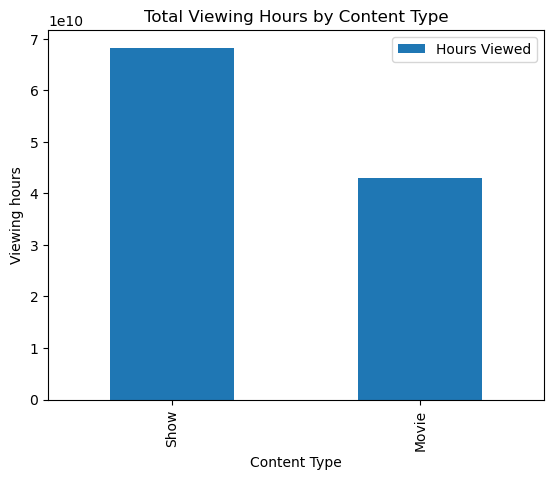

In [186]:
result.plot(kind="bar", title="Total Viewing Hours by Content Type", ylabel="Viewing hours", xlabel="Content Type")
plt.legend()
plt.show()

##### Shows generate approximately 68.27 billion viewing hours, compared to 43.07 billion for Movies

In [ ]:
#3 Which content type has the higher average viewing hours per title?

In [188]:
avg_viewing_hours=round(netflix_copy.groupby(by='Content Type')['Hours Viewed'].mean(),2)
avg_viewing_hours.to_frame(name="Average Viewing hours")

,Average Viewing hours
Content Type,
Movie,3391119.51
Show,10575123.92


##### The average viewing hours of Show is 10.57 million while that of movie is 3.39 which is comparatively lower

In [ ]:
#4. What percentage of total viewing hours comes from the top 10 titles?

In [194]:
total_hours = netflix_copy['Hours Viewed'].sum()
top_10_hours = netflix_copy.nlargest(10, "Hours Viewed")["Hours Viewed"].sum()
percentage = (top_10_hours/total_hours)*100
print("Total Viewing Hours:", total_hours)
print("Top 10 title Viewing Hours:", top_10_hours)
print("Contribution of total viewing from top 10 title:", (round(percentage, 2)), "%")


Total Viewing Hours: 111347000000
Top 10 title Viewing Hours: 5300000000
Contribution of total viewing from top 10 title: 4.76 %


##### The top 10 titles contribute to mainly 4.76% of total viewing hours

In [ ]:
#5. Do globally available titles receive more viewing hours than other titles?

In [214]:
viewing_hours_as_per_globally_available = netflix_copy.groupby(by="Available Globally?")["Hours Viewed"].sum()
viewing_hours_as_per_globally_available.to_frame(name="Global Comparision")


,Global Comparision
Available Globally?,
No,50061200000
Yes,61285800000


##### Globally Available titles have higher viewing hours of about 61.28 billion total hours

In [ ]:
#6. Which languages generate the highest viewing hours?

In [218]:
Language_summary = netflix_copy.groupby(by="Language Indicator")["Hours Viewed"].agg(Total_viewing_hours='sum').sort_values("Total_viewing_hours",ascending=False)
Language_summary

,Total_viewing_hours
Language Indicator,
English,86196700000
Korean,12057300000
Non-English,7676600000
Japanese,4490300000
Hindi,848900000
Russian,77200000


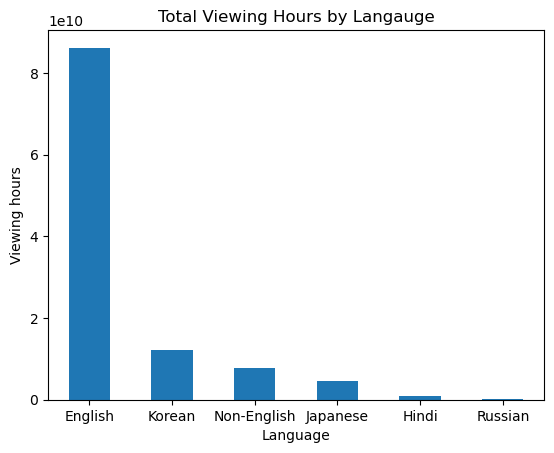

In [222]:
Language_summary["Total_viewing_hours"].plot(kind="bar", title="Total Viewing Hours by Langauge", ylabel="Viewing hours", xlabel="Language", rot=360)
plt.show()

##### English generates the highest viewing hours compared to all other languages, Korean being the second

In [ ]:
#7. How does viewing performance differ between English and non-English content?

In [104]:
average_views = netflix_copy.groupby("Language Indicator")["Hours Viewed"].mean()

print(average_views.loc[["English", "Non-English"]].round(2))

Language Indicator
English        7324518.95
Non-English    3250530.59
Name: Hours Viewed, dtype: float64


##### English content contributes approximately average of 7.32 million viewing hours compared to non-English content

In [ ]:
#8 What is the relationship between release date and viewing hours?

In [107]:
netflix_copy["Release Date"] = pd.to_datetime(netflix_copy["Release Date"], errors="coerce")

In [223]:
round(netflix_copy["Release Date"].corr(netflix_copy["Hours Viewed"]),2)

np.float64(0.21)

##### The correlation between Release date and Viewing Hours is 0.21 which means it hardly depends on the release date

In [ ]:
#9. How many titles have missing release dates?

In [230]:
Missing_release_date = netflix_copy["Release Date"].isnull().sum()
Valid_release_date = netflix_copy["Release Date"].notna().sum()
print("Missing release date:", Missing_release_date)
print("Valid release date:", Valid_release_date)
print(f"Percentage of missing release date: {Missing_release_date/len(netflix_copy)*100:.2f}%")

Missing release date: 14040
Valid release date: 5118
Percentage of missing release date: 73.29%


##### Almost 73.29% of release date are missing

<Axes: xlabel='Release Date', ylabel='Hours Viewed'>

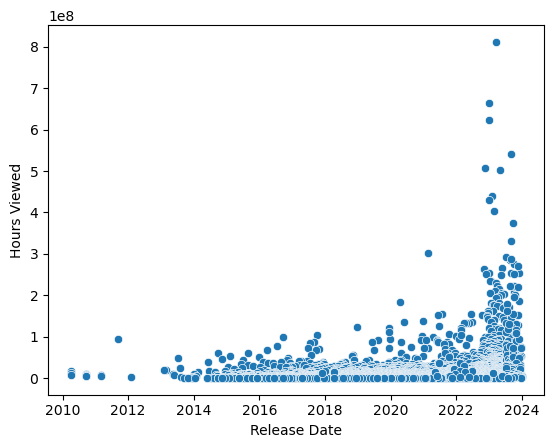

In [235]:
sns.scatterplot(x="Release Date",y="Hours Viewed",data = netflix_copy)

In [236]:
#10. Which content categories deserve further investment research?

In [240]:
investment_research=netflix_copy.groupby(["Language Indicator","Content Type"]).agg(
                    Total_viewing_hours=("Hours Viewed", "sum"),
                    Number_of_Title=("Title","count")
                    ).sort_values("Total_viewing_hours",ascending=False)
investment_research

Total_viewing_hours  Number_of_Title
Language Indicator Content Type                                      
English            Show                  54325200000             4404
                   Movie                 31871500000             8654
Korean             Movie                  6154900000              893
                   Show                   5902400000              453
Non-English        Show                   4694900000              744
Japanese           Show                   3049400000              788
Non-English        Movie                  2981700000             1968
Japanese           Movie                  1440900000              885
Hindi              Movie                   599800000              281
                   Show                    249100000               53
Russian            Show                     52000000               14
                   Movie                    25200000               21

##### 1. English,Non-English,Japanese,Russian Shows have highest viewing hours. As per the dataset this is the strongest scale of opprtunity to grow as compared to movies.
##### 2. On the other hand, Korean and Hindi Movies have highest viewing hours as per the title.
##### 3. Overall English Show displays the biggest chunk of opportunity.

<Axes: xlabel='Language Indicator', ylabel='Hours Viewed'>

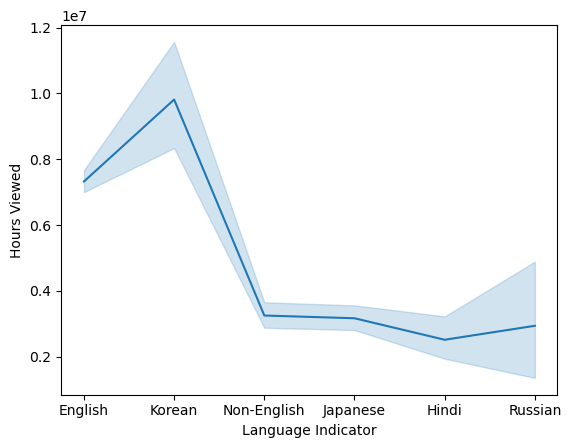

In [121]:
sns.lineplot(x="Language Indicator",y="Hours Viewed", data=netflix_copy)

<Axes: xlabel='Content Type', ylabel='Hours Viewed'>

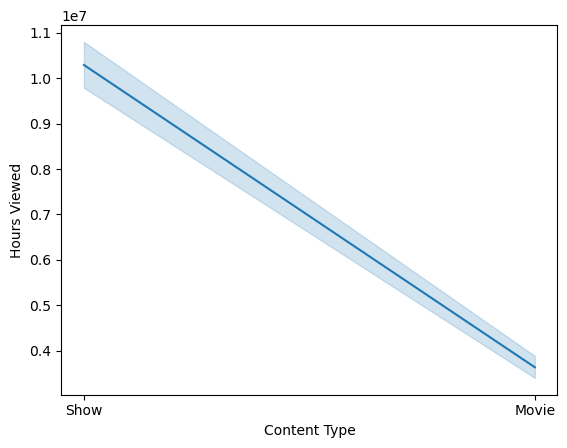

In [123]:
sns.lineplot(x="Content Type",y="Hours Viewed", data=netflix_copy)

##### Limitations: 
##### 1. 14040 release dates are missing hence the correlation between release date and viewing hours is unreliable.
